# Research questions

Inputs: `results/metrics/<variant>/rq*/` (run_metrics_pipeline.sh). Plots: `results/plots/rq*_*`. Titles only in PNG.

In [ ]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from utils import constants as cons
from viz import rq_plots
from viz.figures import save_figure
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [ ]:
# Parameters
SMOKE = True                                   # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # metrics/<VARIANT> (robustness checks: 'robustness/<check>')
SAVE = False
FORMATS = ['png']                              # e.g. ['png', 'pdf']
RQ1_MEASURE = 'omega2'                     # 'shapley_r2' (shares, + residual) | 'omega2' (partial omega^2)
RQ1_METRICS = None                             # None (all) | a family / subgroup ('technical', 'factuality') | [metric keys]
RQ2_VALUE = 'deviation'                        # bars: 'deviation' (from the grand mean) | 'emm' (estimated marginal mean)
RQ2_FOREST = 'contrast'                        # forest: 'contrast' (vs the reference value) | 'deviation'
RQ2_METRICS = None                             # heatmap columns: None (all) | a family / subgroup | [metric keys]
RQ3_TECHNICAL = cons.RQ3_TECHNICAL_METRICS        # x axis: summed; refusals, duplicates as 1 - x
RQ3_SOCIAL = cons.RQ3_SOCIAL_METRICS              # y axis: summed (default: the 6 parities)
RQ3_PARETO = False                             # dotted line through the Pareto front
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
METRICS_DIR = RESULTS_DIR / 'metrics' / VARIANT
PLOTS_DIR = RESULTS_DIR / 'plots'
CONFIG = PROJECT / 'config' / ('analysis_smoke.yaml' if SMOKE else 'analysis.yaml')
from utils import analysis_config
analysis_config.require_late_reviewed(CONFIG)  # RQs need the late settings (thresholds, valid tags) reviewed

## RQ1. Global influence of each variable

In [ ]:
# Data: partial omega^2 and Shapley R^2 of the model and of every configuration variable, per metric
rq1 = rq_plots.load_rq1(METRICS_DIR / 'rq1')
print(f"{rq1['metric'].nunique()} metrics | {rq1['n_models'].max()} models | {rq1['n_configs'].max():,} configurations")

26 metrics | 3 models | 6,480 configurations


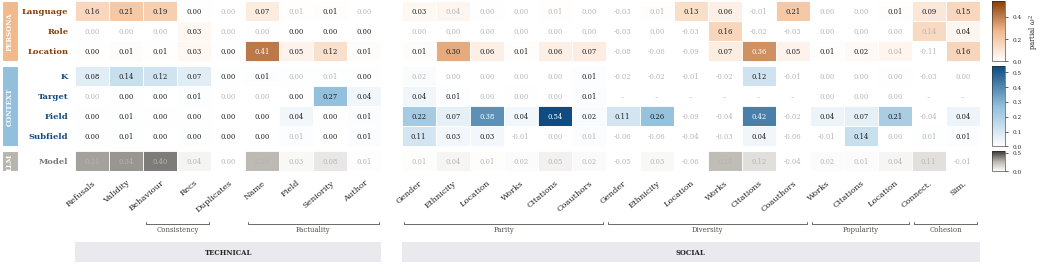

In [ ]:
# Heatmap: RQ1_METRICS (TECHNICAL | SOCIAL); faded = 95% CI includes 0; Shapley R^2 adds the residual (1 - R^2)
fig = rq_plots.plot_rq1_heatmap(rq1, RQ1_MEASURE, RQ1_METRICS)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('heatmap', RQ1_MEASURE, RQ1_METRICS), PLOTS_DIR, FORMATS)

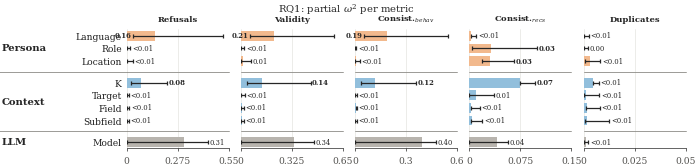

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'technical'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

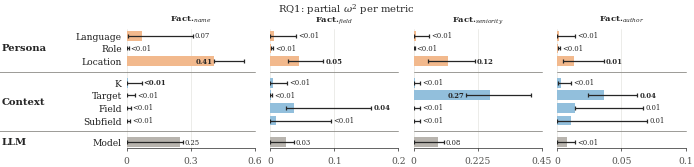

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'factuality'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

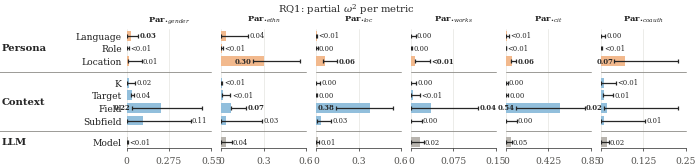

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'parity'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

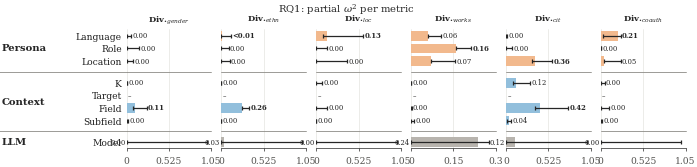

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'diversity'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

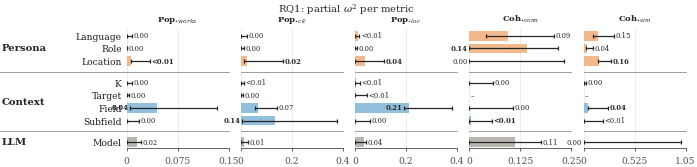

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = 'popularity_cohesion'
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bars', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

In [ ]:
# Table: RQ1_MEASURE [CI] per variable and metric
rq1.assign(value=rq1.apply(lambda r: f"{r[RQ1_MEASURE]:.3f} [{r[RQ1_MEASURE + '_ci_low']:.3f}, {r[RQ1_MEASURE + '_ci_high']:.3f}]", axis=1)) \
   .pivot(index='variable', columns='metric', values='value')

metric,behaviour_consistency,connectedness,diversity_collaboration,diversity_ethnicity,diversity_gender,diversity_influence,diversity_location,diversity_productivity,duplicates,factuality_author,...,parity_influence,parity_location,parity_productivity,popularity_influence,popularity_location,popularity_productivity,recommendation_consistency,refusals,similarity,validity
variable,,,,,,,,,,,,,,,,,,,,,
field,"0.004 [0.003, 0.010]","-0.037 [-0.037, 0.107]","-0.018 [-0.053, 0.102]","0.258 [0.258, 0.345]","0.108 [0.078, 0.248]","0.420 [0.360, 0.770]","-0.089 [-0.089, 0.135]","-0.039 [-0.039, 0.002]","0.002 [0.001, 0.008]","0.014 [0.014, 0.067]",...,"0.538 [0.103, 0.793]","0.379 [0.138, 0.543]","0.035 [0.000, 0.119]","0.069 [0.054, 0.141]","0.212 [0.194, 0.381]","0.044 [0.006, 0.133]","0.002 [0.002, 0.016]","0.003 [0.001, 0.015]","0.043 [0.043, 0.252]","0.006 [0.003, 0.019]"
k,"0.116 [0.036, 0.359]","-0.029 [-0.029, 0.058]","-0.013 [-0.013, 0.046]","-0.023 [-0.027, -0.002]","-0.019 [-0.027, 0.005]","0.120 [0.087, 0.295]","-0.012 [-0.017, 0.077]","-0.022 [-0.022, -0.006]","0.005 [0.004, 0.007]","0.003 [0.001, 0.011]",...,"-0.002 [-0.004, 0.016]","-0.001 [-0.003, 0.027]","-0.003 [-0.004, 0.009]","0.002 [-0.004, 0.013]","0.002 [-0.000, 0.018]","-0.003 [-0.004, 0.009]","0.074 [0.074, 0.096]","0.075 [0.025, 0.216]","-0.003 [-0.019, 0.030]","0.136 [0.039, 0.444]"
language,"0.187 [0.053, 0.549]","0.095 [0.042, 0.208]","0.208 [0.025, 0.245]","0.008 [-0.012, 0.115]","-0.027 [-0.038, 0.060]","-0.009 [-0.036, 0.016]","0.128 [0.085, 0.580]","0.061 [0.061, 0.107]","0.000 [-0.000, 0.003]","0.002 [-0.000, 0.014]",...,"0.006 [-0.004, 0.027]","0.002 [-0.000, 0.007]","-0.002 [-0.004, 0.008]","-0.002 [-0.004, 0.024]","0.010 [0.001, 0.017]","-0.002 [-0.004, 0.008]","0.003 [0.002, 0.010]","0.155 [0.033, 0.520]","0.154 [0.093, 0.313]","0.209 [0.061, 0.595]"
location,"0.006 [0.001, 0.027]","-0.114 [-0.114, 0.233]","0.045 [0.045, 0.245]","-0.055 [-0.055, 0.101]","-0.079 [-0.101, 0.080]","0.356 [0.327, 0.571]","-0.085 [-0.111, 0.378]","0.071 [0.071, 0.157]","0.003 [0.001, 0.008]","0.013 [0.004, 0.036]",...,"0.061 [0.053, 0.100]","0.059 [0.047, 0.150]","0.006 [0.006, 0.033]","0.024 [0.012, 0.166]","0.041 [-0.007, 0.114]","0.006 [0.006, 0.034]","0.031 [0.019, 0.066]","0.005 [0.000, 0.036]","0.164 [0.152, 0.282]","0.013 [0.002, 0.068]"
model,"0.395 [-0.000, 0.475]","0.112 [-0.429, 0.176]","-0.040 [-0.250, 1.000]","0.027 [-0.111, 1.000]","-0.049 [-1.750, 1.000]","0.116 [-0.057, 1.000]","-0.056 [-0.100, 1.000]","0.239 [-0.111, 0.274]","0.001 [-0.000, 0.002]","0.007 [-0.000, 0.014]",...,"0.051 [-0.005, 0.056]","0.010 [-0.005, 0.023]","0.016 [-0.005, 0.022]","0.014 [-0.005, 0.028]","0.037 [-0.005, 0.041]","0.015 [-0.005, 0.022]","0.041 [-0.000, 0.057]","0.311 [-0.000, 0.438]","-0.012 [-0.200, 1.000]","0.338 [-0.000, 0.469]"
role,"0.001 [-0.000, 0.007]","0.142 [-0.025, 0.218]","-0.026 [-0.026, -0.001]","-0.004 [-0.004, 0.089]","-0.026 [-0.028, 0.158]","-0.020 [-0.028, 0.079]","-0.027 [-0.027, 0.138]","0.158 [0.158, 0.213]","-0.000 [-0.000, 0.002]","0.001 [0.001, 0.002]",...,"0.001 [-0.002, 0.003]","-0.002 [-0.002, 0.009]","-0.002 [-0.002, 0.001]","-0.002 [-0.002, 0.014]","-0.001 [-0.002, 0.006]","-0.002 [-0.002, 0.001]","0.032 [0.004, 0.100]","0.001 [-0.000, 0.021]","0.038 [0.022, 0.095]","0.002 [-0.000, 0.023]"
seniority,"0.002 [0.000, 0.010]","nan [nan, nan]","nan [nan, nan]","nan [nan, nan]","nan [nan, nan]","nan [nan, nan]","nan [nan, nan]","nan [nan, nan]","0.001 [-0.000, 0.008]","0.036 [0.024, 0.062]",...,"-0.001 [-0.002, 0.019]","-0.001 [-0.002, 0.003]","0.003 [-0.000, 0.016]","-0.000 [-0.002, 0.007]","0.001 [-0.001, 0.046]","-0.000 [-0.002, 0.004]","0.010 [0.000, 0.036]","0.002 [-0.000, 0.012]","nan [nan, nan]","0.004 [0.000, 0.026]"
subfield,"0.002 [0.001, 0.011]","0.005 [-0.058, 0.056]","-0.059 [-0.059, 0.014]","-0.062 [-0.083, -0.020]","-0.064 [-0.064, 0.019]","0.036 [0.017, 0.068]","-0.044 [-0.055, -0.003]","-0.028 [-0.028, 0.010]","0.002 [0.001, 0.013]"

## RQ2. Local influence of each value

In [ ]:
# Data: EMM and deviation from the grand mean of every value of every configuration variable, per metric
rq2 = rq_plots.load_rq2(METRICS_DIR / 'rq2')
print(f"{rq2['metric'].nunique()} metrics | {rq2['n_models'].max()} models | {rq2['n_configs'].max():,} configurations")


26 metrics | 3 models | 6,480 configurations


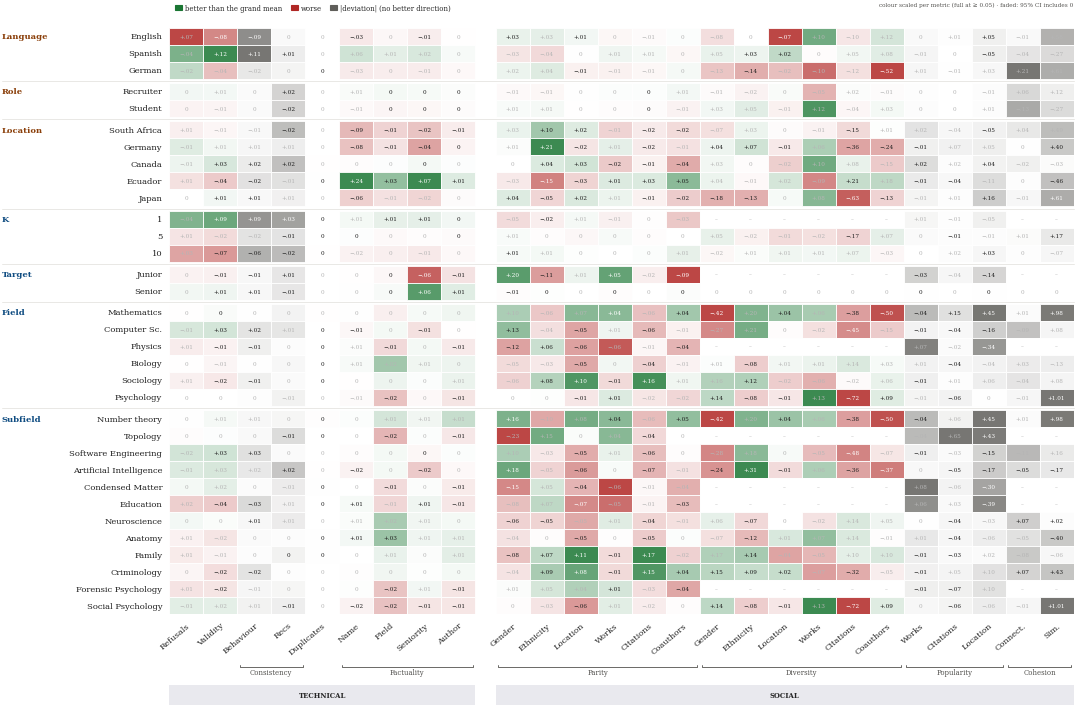

In [ ]:
# Heatmap: deviations, green = better than the grand mean, red = worse, grey = no better direction; faded = CI includes 0
fig = rq_plots.plot_rq2_heatmap(rq2, RQ2_METRICS)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('heatmap', 'deviation', RQ2_METRICS), PLOTS_DIR, FORMATS)


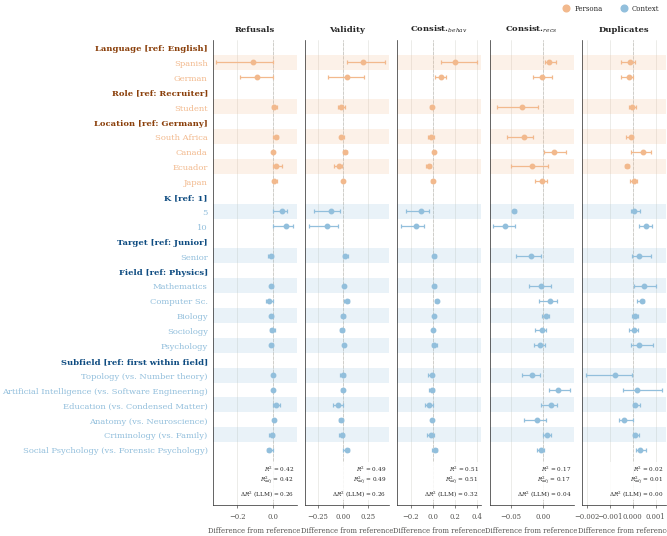

In [ ]:
# Forest: one dot + 95% CI per value, technical metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'technical'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


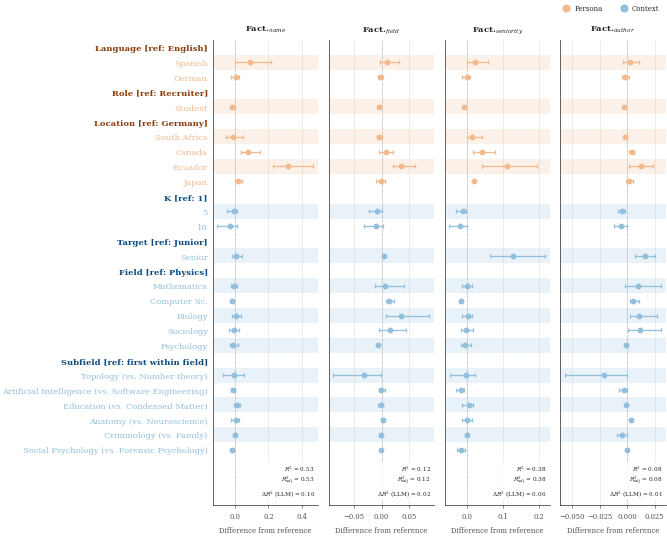

In [ ]:
# Forest: one dot + 95% CI per value, factuality metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'factuality'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


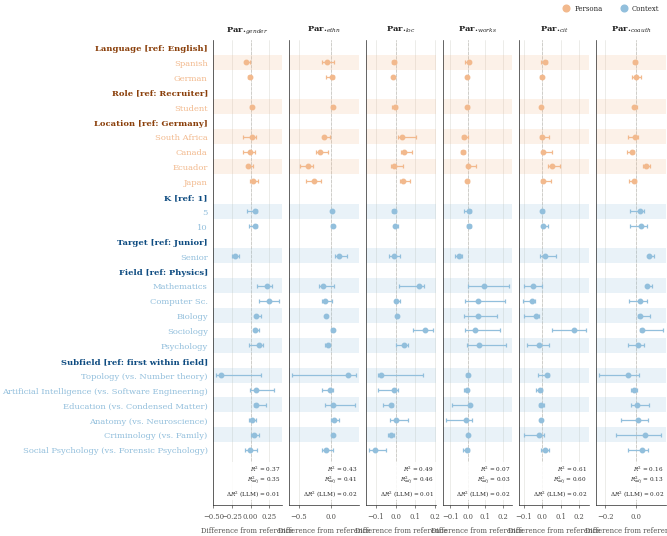

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'parity'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


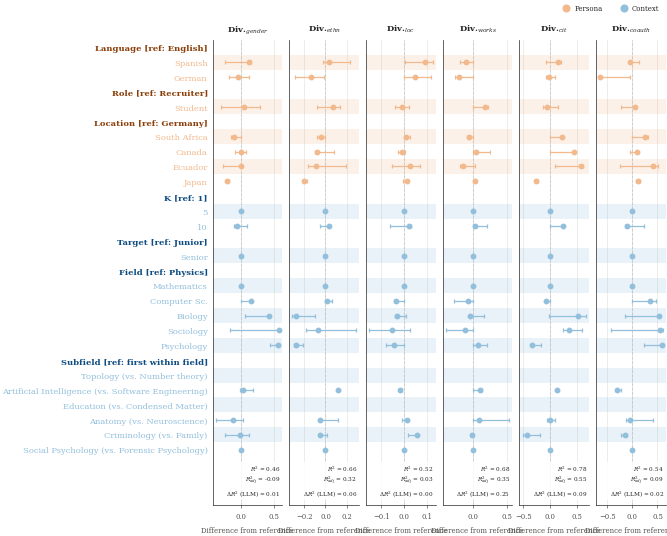

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'diversity'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


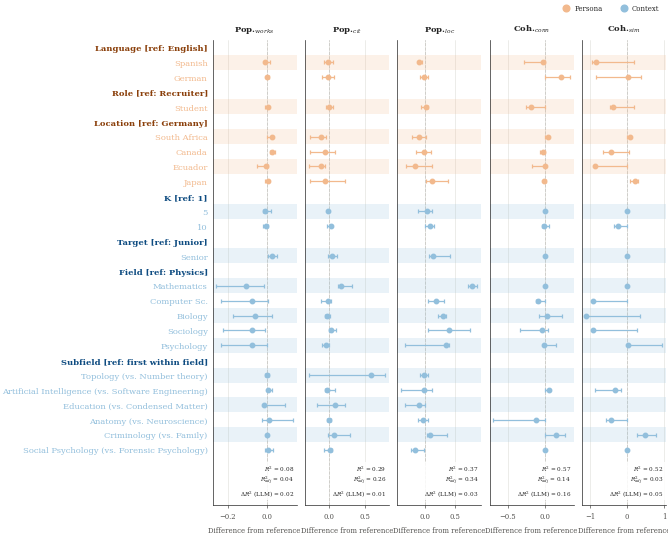

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = 'popularity_cohesion'
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


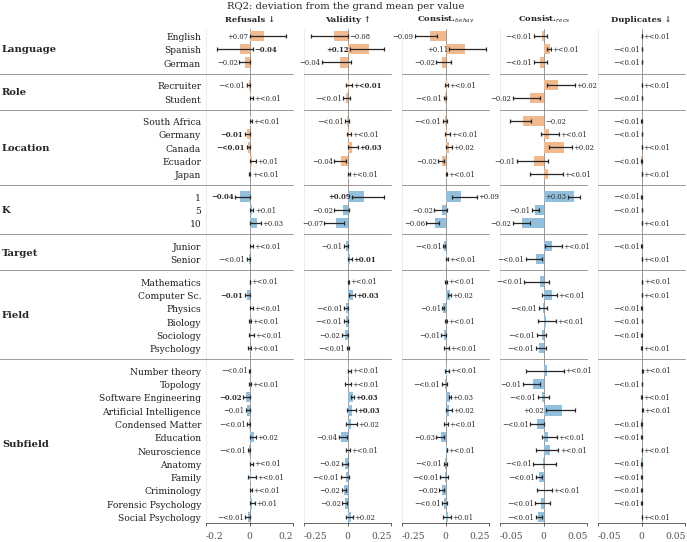

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'technical'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


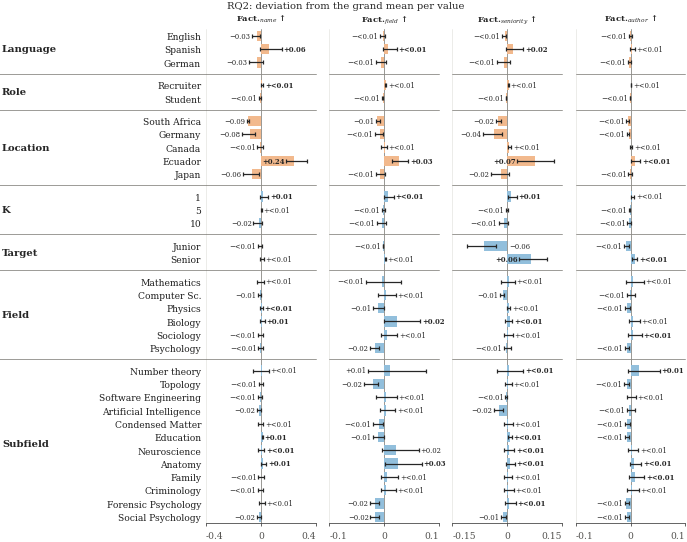

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'factuality'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


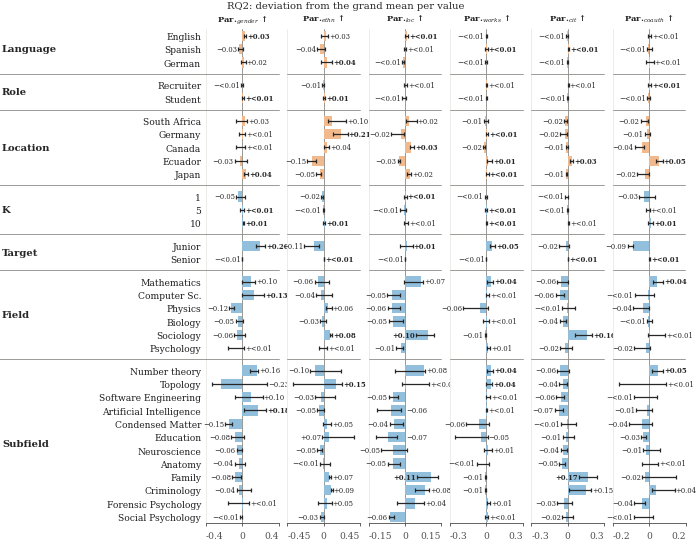

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'parity'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


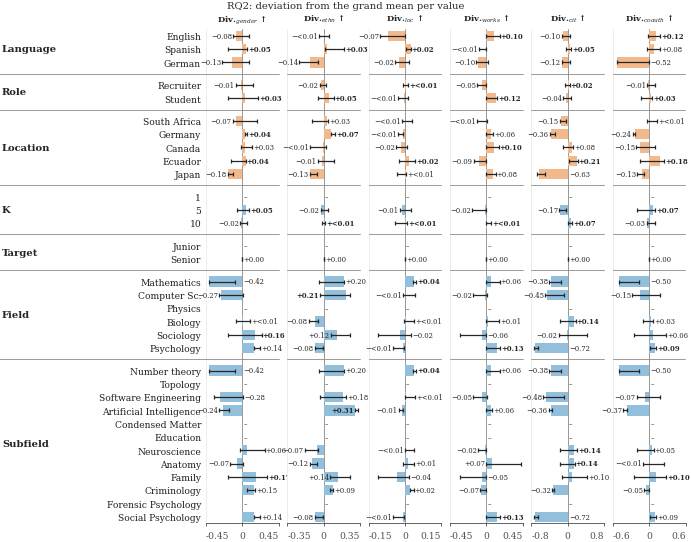

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'diversity'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


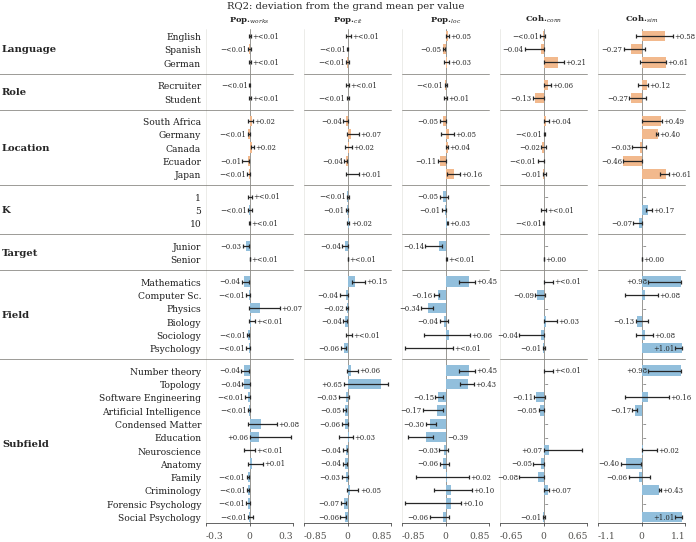

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'popularity_cohesion'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('bars', RQ2_VALUE, group_metric), PLOTS_DIR, FORMATS)


## RQ3. Socio-technical trade-off

In [ ]:
# Data: per model, the mean of each metric over its configurations; technical / social score = their sums
from analysis import tradeoff
from metrics import summary
rq3 = tradeoff.model_scores(summary.configuration_table(METRICS_DIR), RQ3_TECHNICAL, RQ3_SOCIAL)
rq3.assign(quadrant_relative=tradeoff.quadrants(rq3, 'relative'), quadrant_absolute=tradeoff.quadrants(rq3, 'absolute'),
           pareto=tradeoff.pareto_front(rq3)).sort_values('technical', ascending=False).round(3)


,model,validity,refusals,duplicates,factuality_name,factuality_name_field,factuality_name_seniority,factuality_author,parity_gender,parity_ethnicity,...,parity_influence,parity_collaboration,technical,social,technical_max,social_max,n_missing,quadrant_relative,quadrant_absolute,pareto
1,gemma3-4b-it-q4_K_M,0.943,1.000,1.0,0.133,0.012,0.053,0.004,0.420,0.304,...,0.355,0.411,3.144,2.536,7,6,0,Q1,Q3,True
2,phi4-reasoning-14b-q4_K_M,0.682,0.817,1.0,0.308,0.037,0.110,0.013,0.369,0.244,...,0.415,0.369,2.966,2.474,7,6,0,Q4,Q3,False
0,deepseek-r1-8b-0528-qwen3-q4_K_M,0.680,0.920,1.0,0.124,0.019,0.033,0.008,0.451,0.344,...,0.356,0.401,2.784,2.647,7,6,0,Q2,Q3,True


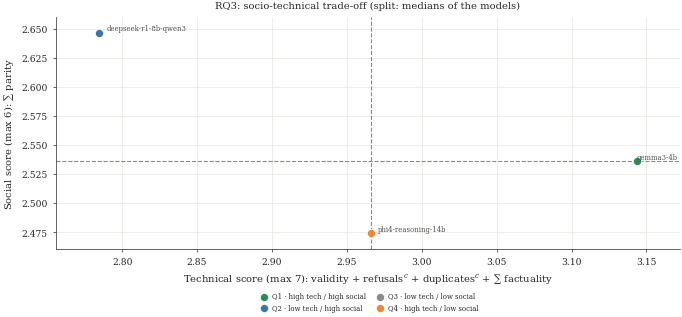

In [ ]:
# Relative: quadrants split at the medians of the models
fig = rq_plots.plot_rq3(rq3, 'relative', RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL)
if SAVE:
    save_figure(fig, rq_plots.rq3_figure_name('relative', RQ3_TECHNICAL, RQ3_SOCIAL), PLOTS_DIR, FORMATS)


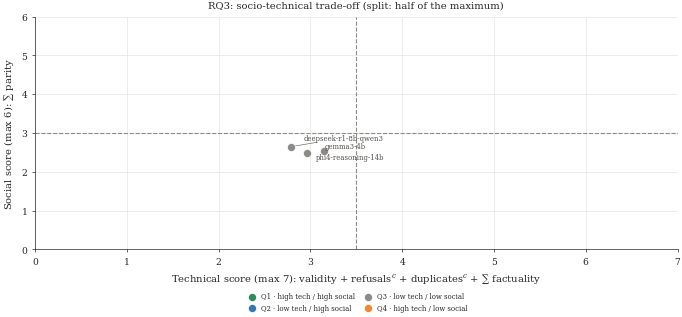

In [ ]:
# Absolute: quadrants split at half of each axis maximum (axes from 0 to the maximum)
fig = rq_plots.plot_rq3(rq3, 'absolute', RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL)
if SAVE:
    save_figure(fig, rq_plots.rq3_figure_name('absolute', RQ3_TECHNICAL, RQ3_SOCIAL), PLOTS_DIR, FORMATS)
